# 横磁場イジングモデル：クエンチ後の横磁化$m_x(t)$

初期状態$\ket{+\cdots+}$（$J=0$の基底状態）から、横磁場イジングモデルのハミルトニアン$H$で時間発展させたときの横磁化$m_x(t)$を、厳密対角化・Jordan-Wigner変換・Trotter分解（量子回路）で求めて比較する。模型の定義は [00_model.ipynb](00_model.ipynb)、各手法のTFIMへの適用は [01_exact_diag](01_exact_diag.ipynb)・[02_jordan_wigner](02_jordan_wigner.ipynb)・[03_trotter](03_trotter.ipynb)・[04_vqe](04_vqe.ipynb)、手法の一般論は [methods/](../../methods/) を参照。

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# 厳密対角化（src/qmb/operators.py, ed.py）と TFIM の定義（src/qmb/models.py）
from qmb.operators import plus_state
from qmb.ed import ground_state, time_evolve_expectation
from qmb.models import tfim_hamiltonian as hamiltonian, magnetization_x
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector

# 各手法の TFIM への適用（src/qmb/models.py, circuits.py）
from qmb.models import tfim_ground_energy_ff as ground_energy_jw, tfim_mx_quench_ff as mx_jw
from qmb.circuits import tfim_op, mx_op, plus_circuit, trotter_step, mx_trotter, vqe
# 実装を見たいときは、Jupyterで関数名の後に ?? を付けて実行する（例: tfim_hamiltonian??）

## 1. 厳密対角化とJordan-Wigner変換の比較

$n=10$で、厳密対角化（$1024\times1024$行列）とJordan-Wigner変換（$20\times20$行列）を比較する。

m_x(t) の最大誤差 = 5.22e-15


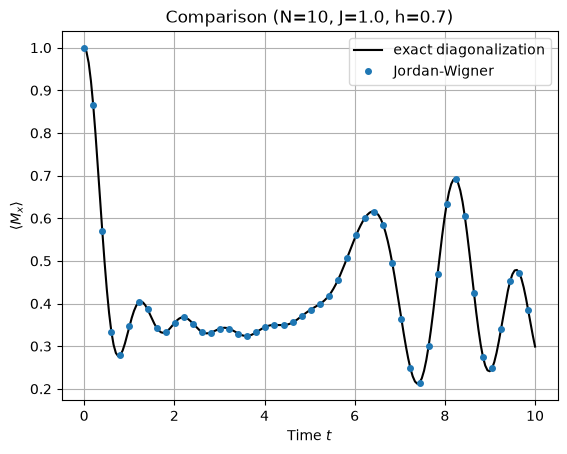

In [2]:
N = 10
J = 1.0
h = 0.7
ts = np.linspace(0, 10, 200)

H = hamiltonian(N, J, h)
mx_ed = time_evolve_expectation(H, plus_state(N), magnetization_x(N), ts)
mx_f = mx_jw(N, J, h, ts)
print(f"m_x(t) の最大誤差 = {np.max(np.abs(mx_ed - mx_f)):.2e}")

plt.plot(ts, mx_ed, "k-", label="exact diagonalization")
plt.plot(ts[::4], mx_f[::4], "o", ms=4, label="Jordan-Wigner")
plt.xlabel("Time $t$")
plt.ylabel(r"$\langle M_x \rangle$")
plt.title(f"Comparison (N={N}, J={J}, h={h})")
plt.legend()
plt.grid()
plt.show()

2つの手法は数値誤差の範囲で一致している。

## 2. 大きな$n$での時間発展

Jordan-Wigner変換なら、厳密対角化では扱えない$n=100$（$2^{100}\approx10^{30}$次元）も$200\times200$行列で計算できる。いくつかの$h$で$m_x(t)$を描く。

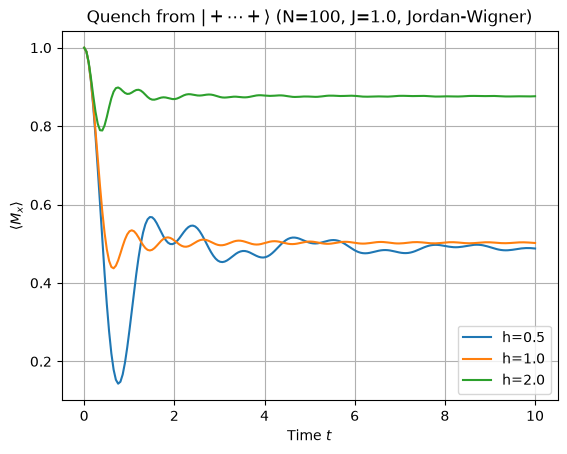

In [3]:
N = 100
J = 1.0
ts = np.linspace(0, 10, 200)

for h in [0.5, 1.0, 2.0]:
    plt.plot(ts, mx_jw(N, J, h, ts), label=f"h={h}")
plt.xlabel("Time $t$")
plt.ylabel(r"$\langle M_x \rangle$")
plt.title(f"Quench from $|+\\cdots+\\rangle$ (N={N}, J={J}, Jordan-Wigner)")
plt.legend()
plt.grid()
plt.show()

$n=2$では$m_x(t)$がきれいに振動し続けたが（[01_exact_diag.ipynb](01_exact_diag.ipynb)）、$n$が大きいと多数のモード$\varepsilon_k$の振動が重なって打ち消し合い、$m_x(t)$は振動しながらある値に落ち着いていく。

## 3. Trotter分解（量子回路）との比較

$n=10$で、Trotter分解の時間刻み$\delta t$を変えて厳密対角化と比較する。

δt = 0.50: m_x(t) の最大誤差 = 5.30e-01
δt = 0.10: m_x(t) の最大誤差 = 2.09e-02


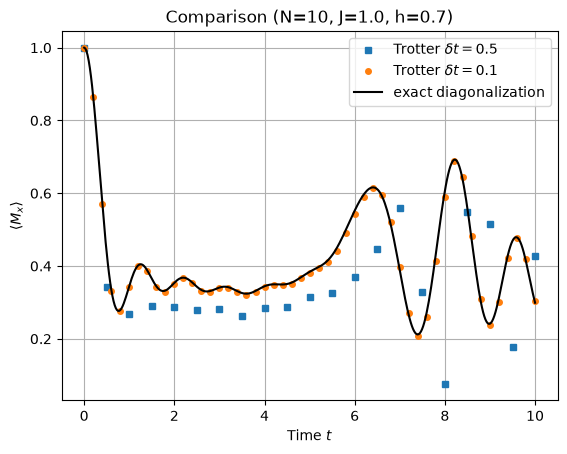

In [4]:
N = 10
J = 1.0
h = 0.7
t_max = 10

H = hamiltonian(N, J, h, pbc=False)
for r, mk in [(20, "s"), (100, "o")]:
    ts_r, mx_r = mx_trotter(N, J, h, t_max, r)
    mx_ex = time_evolve_expectation(H, plus_state(N), magnetization_x(N), ts_r)
    print(f"δt = {t_max / r:.2f}: m_x(t) の最大誤差 = {np.max(np.abs(mx_r - mx_ex)):.2e}")
    every = max(1, r // 50)
    plt.plot(ts_r[::every], mx_r[::every], mk, ms=4, label=rf"Trotter $\delta t={t_max / r}$")

ts = np.linspace(0, t_max, 400)
plt.plot(ts, time_evolve_expectation(H, plus_state(N), magnetization_x(N), ts), "k-", label="exact diagonalization")
plt.xlabel("Time $t$")
plt.ylabel(r"$\langle M_x \rangle$")
plt.title(f"Comparison (N={N}, J={J}, h={h})")
plt.legend()
plt.grid()
plt.show()

$\delta t = 0.1$では厳密対角化とよく一致するが、$\delta t = 0.5$では$n=2$のとき（[03_trotter.ipynb](03_trotter.ipynb)）より大きくずれる。サイト数が増えると交換しない項の組が増え、$[H_{ZZ}, H_X]$が大きくなるためである。

## 4. Trotter誤差とステップ数の関係

ステップ数$r$を変えて誤差がどう縮むかを調べる。[03_trotter.ipynb](03_trotter.ipynb)の2節の議論が正しければ、$m_x$の誤差は1次でも2次でも同じで、$r^{-2}$に比例するはずである。比較のため、状態そのものの誤差（不忠実度$1-|\bra{\psi_{\mathrm{exact}}}\ket{\psi_{\mathrm{Trotter}}}|^2$）も計算する。

1次: m_x の誤差 = [2.56479464e-01 6.15631788e-02 1.55086024e-02 3.85476272e-03
 9.63141674e-04 2.40753772e-04]
2次: m_x の誤差 = [2.56479464e-01 6.15631788e-02 1.55086024e-02 3.85476272e-03
 9.63141674e-04 2.40753772e-04]


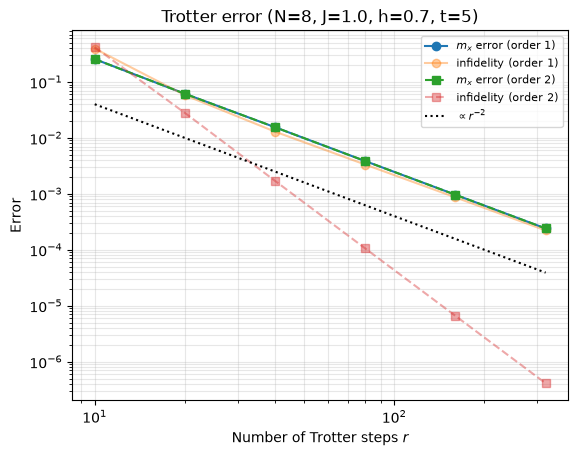

In [5]:
N = 8
J = 1.0
h = 0.7
t_max = 5
H = hamiltonian(N, J, h, pbc=False)
rs = np.array([10, 20, 40, 80, 160, 320])

# 厳密な終状態 e^{-iHt}|+...+>（Qiskitの並び順で計算）
w, v = np.linalg.eigh(tfim_op(N, J, h).to_matrix())
psi_init = Statevector(plus_circuit(N)).data
psi_exact = v @ (np.exp(-1j * w * t_max) * (v.conj().T @ psi_init))

for order, mk in [(1, "o-"), (2, "s--")]:
    mx_err, infid = [], []
    for r in rs:
        ts_r, mx_r = mx_trotter(N, J, h, t_max, r, order)
        mx_ex = time_evolve_expectation(H, plus_state(N), magnetization_x(N), ts_r)
        mx_err.append(np.max(np.abs(mx_r - mx_ex)))
        sv = Statevector(plus_circuit(N))
        step = trotter_step(N, J, h, t_max / r, order)
        for _ in range(r):
            sv = sv.evolve(step)
        infid.append(1 - abs(np.vdot(psi_exact, sv.data))**2)
    plt.loglog(rs, mx_err, mk, label=rf"$m_x$ error (order {order})")
    plt.loglog(rs, infid, mk, alpha=0.4, label=f"infidelity (order {order})")
    print(f"{order}次: m_x の誤差 = {np.array(mx_err)}")

plt.loglog(rs, 4 / rs**2, "k:", label=r"$\propto r^{-2}$")
plt.xlabel("Number of Trotter steps $r$")
plt.ylabel("Error")
plt.title(f"Trotter error (N={N}, J={J}, h={h}, t={t_max})")
plt.legend(fontsize=8)
plt.grid(which="both", alpha=0.3)
plt.show()

$m_x$の誤差は1次と2次で完全に一致し、どちらも$r^{-2}$に比例している。一方、状態の不忠実度は2次の方が速く小さくなる（不忠実度は状態の誤差の2乗程度なので、1次では$r^{-2}$、2次では$r^{-4}$）。

## 5. 測定のサンプリングによる推定

実際の量子コンピュータと同じように、**測定のサンプリング**で$m_x$を推定してみる。$H$ゲートをかけて$Z$基底で測定し、$X_j = 1-2b_j$の平均をとる。

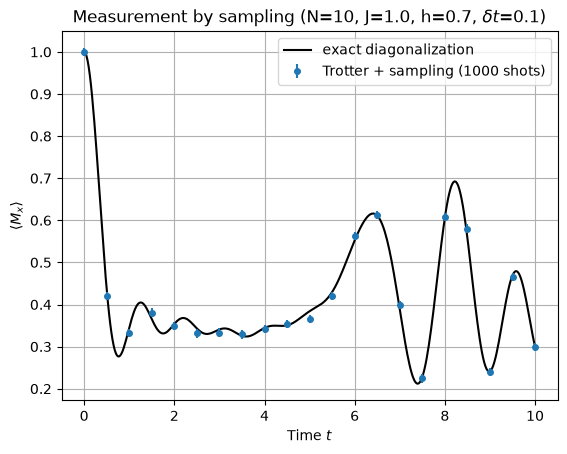

In [6]:
N = 10
J = 1.0
h = 0.7
t_max = 10
r = 100
shots = 1000

dt = t_max / r
step = trotter_step(N, J, h, dt)
had = QuantumCircuit(N)
had.h(range(N))   # X基底での測定のためのアダマールゲート

sv = Statevector(plus_circuit(N))
ts_shot, mx_shot = [], []
for k in range(r + 1):
    if k % 5 == 0:
        counts = sv.evolve(had).sample_counts(shots)   # Z基底で shots 回測定
        # ビット列の各ビット b_j から X_j = 1 - 2 b_j を計算して平均
        mx_est = sum(cnt * np.mean([1 - 2 * int(b) for b in bits]) for bits, cnt in counts.items()) / shots
        ts_shot.append(k * dt)
        mx_shot.append(mx_est)
    sv = sv.evolve(step)

ts = np.linspace(0, t_max, 400)
H = hamiltonian(N, J, h, pbc=False)
plt.plot(ts, time_evolve_expectation(H, plus_state(N), magnetization_x(N), ts), "k-", label="exact diagonalization")
plt.errorbar(ts_shot, mx_shot, yerr=1 / np.sqrt(shots * N), fmt="o", ms=4, label=f"Trotter + sampling ({shots} shots)")
plt.xlabel("Time $t$")
plt.ylabel(r"$\langle M_x \rangle$")
plt.title(f"Measurement by sampling (N={N}, J={J}, h={h}, $\\delta t$={dt})")
plt.legend()
plt.grid()
plt.show()

有限回の測定による統計的なばらつきはあるが、厳密な値を再現している（エラーバーは統計誤差の目安$1/\sqrt{N_{\mathrm{shot}}\,n}$）。

## まとめ

- 厳密対角化とJordan-Wigner変換の$m_x(t)$は数値誤差の範囲で一致する。Jordan-Wigner変換なら$n=100$でも計算でき、大きな系で$m_x(t)$が一定値に落ち着いていく様子が見える。
- Trotter分解は、時間刻み$\delta t$を小さくすれば厳密な結果に近づく。今回の初期状態と観測量では、1次と2次の分解で$m_x$が完全に一致し、誤差は$O(\delta t^2)$になる。
- 実機を想定したサンプリングでも、統計誤差の範囲で厳密な値を再現できる。